# 05: Charts

**Goal:** Turn the `recovery_monthly.csv` data into charts that answer the two questions: 
1. How far has monthly ridership recovered relative to the same month in 2019, by mode?
2. Has ridership recovered faster or slower than service supply (revenue hours)?

**Input:** `data/processed/recovery_monthly.csv` (from notebook 03).

**Output:** PNG files in `figures/`.

**Run from the repo root.**

## Setup and load

The data is loaded into a dataframe called `recovery`. Charts will have consistent coloring and style.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

CSV_PATH = "data/processed/recovery_monthly.csv"
OUT_DIR = "figures"

recovery = pd.read_csv(CSV_PATH, parse_dates=["month"])

MODE_NAMES = recovery.drop_duplicates("mode").set_index("mode")["mode_name"].to_dict()
MODE_COLORS = {"LR": "#e96c14", "MB": "#0474ba"}
VRH_COLOR = "0.5"
PRIMARY_COLOR = "0.1"
SECONDARY_COLOR = "0.3"
GRID_COLOR = "0.9"
SOURCE_NOTE = "Source: FTA National Transit Database, TriMet."


plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.edgecolor": GRID_COLOR,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelcolor": SECONDARY_COLOR,
        "xtick.color": SECONDARY_COLOR,
        "ytick.color": SECONDARY_COLOR,
        "text.color": PRIMARY_COLOR,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
    }
)


def add_source(fig):
    fig.text(0.01, -0.02, SOURCE_NOTE, ha="left", fontsize=8, color=SECONDARY_COLOR)


def save_figure(fig, name):
    fig.savefig(f"{OUT_DIR}/{name}.png", dpi=200, bbox_inches="tight")

## Monthly UPT recovery by mode

- This chart directly addresses question 1, illustrating how far monthly ridership has recovered relative to the same month in 2019, by mode.
- Begins with January 2020.

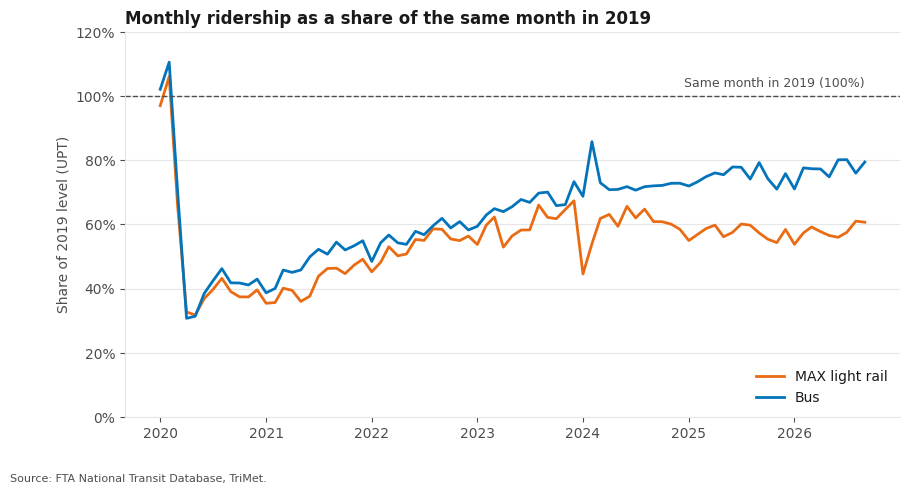

In [2]:
since_2020 = recovery[recovery["month"] >= "2020-01-01"]

fig, ax = plt.subplots(figsize=(10, 5))

for mode, group in since_2020.groupby("mode"):
    ax.plot(
        group["month"],
        group["upt_recovery_monthly"],
        label=MODE_NAMES[mode],
        color=MODE_COLORS[mode],
        linewidth=2,
    )

ax.axhline(1.0, color=SECONDARY_COLOR, linewidth=1, linestyle="--")

ax.text(
    since_2020["month"].max(),
    1.02,
    "Same month in 2019 (100%)",
    ha="right",
    va="bottom",
    fontsize=9,
    color=SECONDARY_COLOR,
)

ax.set_ylim(0, 1.2)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)

ax.set_title("Monthly ridership as a share of the same month in 2019")
ax.set_ylabel("Share of 2019 level (UPT)")
ax.legend(frameon=False, loc="lower right")

add_source(fig)
save_figure(fig, "01_monthly_upt_recovery")
plt.show()

## Rolling 12 month UPT vs VRH recovery

- This chart addresses question 2, comparing each month's 12-month total with calendar-year 2019, for ridership (UPT) and service (VRH).
- Begins with December 2019, the first month with 12 months of data.

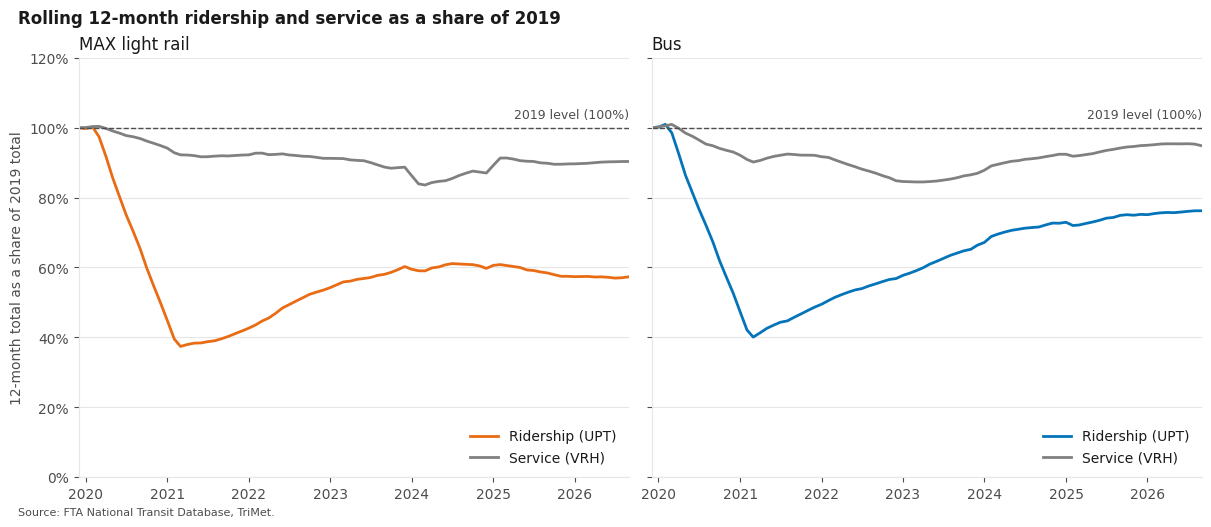

In [3]:
rolling = recovery[recovery["month"] >= "2019-12-01"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, constrained_layout=True)

for ax, (mode, group) in zip(axes, rolling.groupby("mode")):
    ax.plot(
        group["month"],
        group["upt_recovery_rolling"],
        label="Ridership (UPT)",
        color=MODE_COLORS[mode],
        linewidth=2,
    )
    ax.plot(
        group["month"],
        group["vrh_recovery_rolling"],
        label="Service (VRH)",
        color=VRH_COLOR,
        linewidth=2,
    )

    ax.axhline(1.0, color=SECONDARY_COLOR, linewidth=1, linestyle="--")
    ax.text(
        group["month"].max(),
        1.02,
        "2019 level (100%)",
        ha="right",
        va="bottom",
        fontsize=9,
        color=SECONDARY_COLOR,
    )

    ax.set_title(MODE_NAMES[mode], fontweight="normal")

    ax.set_ylim(0, 1.2)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.margins(x=0)

    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="lower right")

axes[0].set_ylabel("12-month total as a share of 2019 total")

fig.suptitle(
    "Rolling 12-month ridership and service as a share of 2019",
    x=0.01,
    ha="left",
    fontweight="bold",
)

add_source(fig)
save_figure(fig, "02_rolling_recovery_upt_vs_vrh")
plt.show()

## Rolling 12 month trips per revenue hour

- This chart also addresses question 2, using our calculated trips per revenue hour column to visualize the ratio over time.
- Each panel has its own y-axis, because the two modes differ in scale. The dashed line marks each mode's 2019 level.
- Begins with December 2019, the first month with 12 months of data.

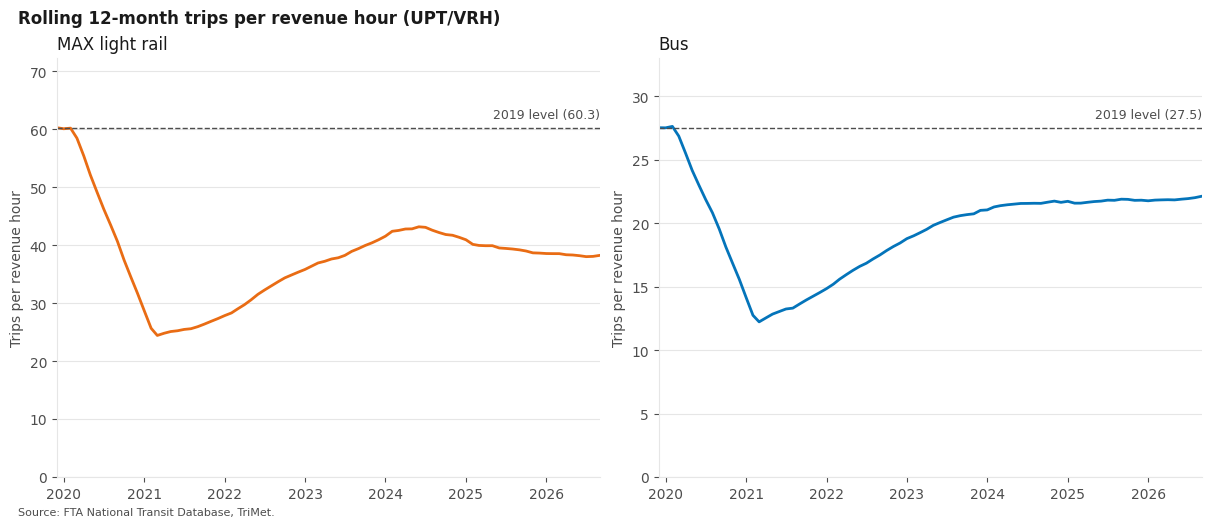

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for ax, (mode, group) in zip(axes, rolling.groupby("mode")):
    baseline = group.loc[group["month"] == "2019-12-01", "upt_per_vrh_rolling"].iloc[0]

    ax.plot(
        group["month"],
        group["upt_per_vrh_rolling"],
        color=MODE_COLORS[mode],
        linewidth=2,
    )

    ax.axhline(baseline, color=SECONDARY_COLOR, linewidth=1, linestyle="--")
    ax.text(
        group["month"].max(),
        baseline * 1.02,
        f"2019 level ({baseline:.1f})",
        ha="right",
        va="bottom",
        fontsize=9,
        color=SECONDARY_COLOR,
    )

    ax.set_title(MODE_NAMES[mode], fontweight="normal")

    ax.set_ylabel("Trips per revenue hour")
    ax.set_ylim(0, baseline * 1.2)

    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.margins(x=0)

    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

fig.suptitle(
    "Rolling 12-month trips per revenue hour (UPT/VRH)",
    x=0.01,
    ha="left",
    fontweight="bold",
)

add_source(fig)
save_figure(fig, "03_rolling_trips_per_revenue_hour")
plt.show()

## Key values behind the charts

- Print some exact months and values to aid interpretation of the charts.
- Output the trough and later peak of rolling UPT recovery and the low point of rolling trips per revenue hour.
- Also check the months where VRH rolling recovery was not above rolling UPT recovery.

In [5]:
for mode, group in rolling.groupby("mode"):
    low = group.loc[group["upt_recovery_rolling"].idxmin()]
    after_low = group[group["month"] > low["month"]]
    peak = after_low.loc[after_low["upt_recovery_rolling"].idxmax()]
    trips_low = group.loc[group["upt_per_vrh_rolling"].idxmin()]

    print(mode)
    print(
        f"  Lowest rolling UPT recovery: {low['month']:%Y-%m}, {low['upt_recovery_rolling']:.3f}"
    )
    print(
        f"  Highest since then: {peak['month']:%Y-%m}, {peak['upt_recovery_rolling']:.3f}"
    )
    print(
        f"  Lowest rolling trips per revenue hour: {trips_low['month']:%Y-%m}, {trips_low['upt_per_vrh_rolling']:.1f}"
    )

vrh_above = rolling["vrh_recovery_rolling"] > rolling["upt_recovery_rolling"]
display(
    rolling.loc[
        ~vrh_above, ["mode", "month", "upt_recovery_rolling", "vrh_recovery_rolling"]
    ]
)

LR
  Lowest rolling UPT recovery: 2021-03, 0.374
  Highest since then: 2024-07, 0.611
  Lowest rolling trips per revenue hour: 2021-03, 24.4
MB
  Lowest rolling UPT recovery: 2021-03, 0.401
  Highest since then: 2026-09, 0.762
  Lowest rolling trips per revenue hour: 2021-03, 12.2


,mode,month,upt_recovery_rolling,vrh_recovery_rolling
11,LR,2019-12-01,1.000000,1.000000
104,MB,2019-12-01,1.000000,1.000000
106,MB,2020-02-01,1.009675,1.005899


## Observations

**Monthly UPT recovery (chart 1)**
- Monthly UPT was above the same month in 2019 only in January and February 2020 (both pre-pandemic). It then fell to its lowest in spring 2020 (see notebook 04).

**Rolling UPT vs VRH recovery (chart 2)**
- Rolling UPT recovery was lowest for the 12 months ending March 2021, at 0.374 for LR and 0.401 for MB.
- Rolling VRH recovery has been above rolling UPT recovery for both modes in every month since March 2020. (The two were equal in December 2019, and MB's rolling UPT recovery was slightly higher than VRH in February 2020, 1.010 vs 1.006.)
- LR's rolling UPT recovery reached 0.611 in July 2024, its highest since the March 2021 low, and was 0.573 in September 2026.
- MB's rolling UPT recovery was 0.762 in September 2026, its highest since the March 2021 low.

**Rolling trips per revenue hour (chart 3)**
- Rolling trips per revenue hour was also lowest for the 12 months ending March 2021, at 24.4 for LR and 12.2 for MB.
- In September 2026, it was 38.25 for LR against 60.27 in 2019, and 22.13 for MB against 27.53 in 2019.